# 03 - Model development and validation

**Notebook 3 of 4.** Goal: choose a model *and* find out how far its reported accuracy can be trusted.

Contents: (1) validation design, (2) reproduce the project's official cross-validation, (3) model comparison, (4) how the hybrid works, (5) why a log target, (6) leakage and legitimacy tests, (7) hyper-parameters, (8) ablations and placebo tests, (9) residual analysis, (10) metric correctness, (11) selection and limits.

All models are the project's own classes (`common.FreightRateModel`, `train_and_predict.NaiveGBM`) evaluated on the project's own folds. Variants are produced by **temporarily patching constants/functions in memory** (a context manager restores them); no source file is modified and no result here is presented as coming from a different implementation than the one used for the submission.

In [1]:
import sys
from pathlib import Path

# Locate the project root (the folder containing common.py) from wherever the kernel was started.
_here = Path.cwd().resolve()
ROOT = next((b for b in [_here, *_here.parents] if (b / "common.py").is_file()),
            next(iter(sorted(p.parent for p in _here.glob("*/common.py"))), None))
assert ROOT is not None, "common.py not found: open this notebook from inside the project folder"
sys.path.insert(0, str(ROOT))

from notebook_support import setup, save_fig, TEAL, GREY, RED, ORANGE

import inspect
from contextlib import contextmanager

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from sklearn.inspection import partial_dependence, permutation_importance
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, mean_squared_error

import common
from common import (COORD_COLS, FreightRateModel, clean_inputs, daily_market_index, days_to_quarter_end, flag_label_outliers,
                    linear_features, load_data, tree_features)
from train_and_predict import FOLDS, N_HELD_OUT_CITIES, NaiveGBM, cross_validate, metrics

# train_and_predict selects the non-interactive Agg backend on import; restore inline plots
%matplotlib inline

P = setup("03_model")
train, valid, template, december = load_data(P["data"])
dmi = daily_market_index(train, valid)                                  # features only, no labels
dqs = pd.concat([train, valid]).groupby("date").quote_signal.mean()     # only used in ablations

@contextmanager
def patched(**attrs):
    """Temporarily replace names inside common.py (constants or functions); always restore them."""
    old = {k: getattr(common, k) for k in attrs}
    for k, v in attrs.items(): setattr(common, k, v)
    try: yield
    finally:
        for k, v in old.items(): setattr(common, k, v)
print("folds defined by the project:", FOLDS)

folds defined by the project: [(6, 8), (7, 9), (8, 10)]


## 1. Validation design

**Question.** How must the data be split so that the error we measure resembles the error we will make on November-December?

**Why it matters.** The wrong split produces confident, wrong numbers.

In [2]:
def make_folds(frame, dmi_series, seed=0):
    """Rebuild the project's folds exactly as train_and_predict.cross_validate does (same RNG stream)."""
    rng = np.random.RandomState(seed)
    cities = sorted(set(frame.pickup) | set(frame.delivery))
    folds = []
    for k, (last_train_month, last_test_month) in enumerate(FOLDS, 1):
        fit_part = frame[frame.date.dt.month <= last_train_month]
        test_part = clean_inputs(frame[(frame.date.dt.month > last_train_month) & (frame.date.dt.month <= last_test_month)])
        held = set(rng.choice(cities, N_HELD_OUT_CITIES, replace=False))
        fit_part = fit_part[~(fit_part.pickup.isin(held) | fit_part.delivery.isin(held))]   # the model never sees these cities
        unseen = (test_part.pickup.isin(held) | test_part.delivery.isin(held)).to_numpy()
        trusted = flag_label_outliers(test_part, dmi_series)                                  # REPORTING ONLY
        folds.append(dict(fold=k, fit=fit_part, test=test_part, unseen=unseen, trusted=trusted, held=sorted(held)))
    return folds

FD = make_folds(train, dmi)
display(pd.DataFrame([{
    "fold": f["fold"], "train period": f"{f['fit'].date.min().date()} to {f['fit'].date.max().date()}", "train rows": len(f["fit"]),
    "test period": f"{f['test'].date.min().date()} to {f['test'].date.max().date()}", "test rows": len(f["test"]),
    "held-out cities (removed from training)": ", ".join(f["held"]),
    "% test rows touching them": 100 * f["unseen"].mean(),
    "test labels flagged corrupted": int((~f["trusted"]).sum())} for f in FD]).set_index("fold"))

,train period,train rows,test period,test rows,held-out cities (removed from training),% test rows touching them,test labels flagged corrupted
fold,,,,,,,
1,2025-01-01 to 2025-06-30,22027,2025-07-01 to 2025-08-31,9671,"Jacksonville, Las Vegas, Little Rock, Los Ange...",24.0926,133
2,2025-01-01 to 2025-07-31,26222,2025-08-01 to 2025-09-30,9429,"Birmingham, El Paso, Greensboro, Lubbock, Okla...",22.4096,132
3,2025-01-01 to 2025-08-31,28479,2025-09-01 to 2025-10-31,9523,"Bakersfield, Baton Rouge, Corpus Christi, Fres...",25.8112,144


**Interpretation.** Each fold trains on the past and tests on the following two months, which is the same horizon as the real task (train Jan-Oct, predict Nov-Dec). Folds are *expanding windows* (later folds have more history), and in every fold eight cities are removed from the training data so that test rows touching them mimic the eight unseen validation cities.

Two honest remarks about this design:
* **It is slightly pessimistic about cities**: 22-26% of test rows touch a held-out city, versus about 12% in the real validation file.
* **It is slightly optimistic about everything else**: only three folds exist, the first test window contains no quarter-end, and *design constants were chosen while looking at the same data* (section 6d). There is no way to build a fold that perfectly imitates a future we cannot see.

*Reporting convention.* 'Trusted' rows are test rows whose label passes the corruption filter; the filter uses the test labels **for reporting only** (it never affects fitting). 'All' rows include corrupted labels. Both are shown everywhere.

## 2. Reproduce the project's official cross-validation

**Question.** Does the number quoted for the final model (clean-label MAPE about 1.77%) come out of the actual code?

**Why it matters.** A reported metric is only worth something if anyone can regenerate it.

In [3]:
official = cross_validate(train, dmi, P["outputs"])
pd.set_option("display.float_format", "{:,.2f}".format)
display(official)

fold 1: train 2025-01-01..2025-06-30 (22,027 rows) -> test 2025-07-01..2025-08-31 (9,671 rows, 24% touch unseen cities)


fold 2: train 2025-01-01..2025-07-31 (26,222 rows) -> test 2025-08-01..2025-09-30 (9,429 rows, 22% touch unseen cities)


fold 3: train 2025-01-01..2025-08-31 (28,479 rows) -> test 2025-09-01..2025-10-31 (9,523 rows, 26% touch unseen cities)


MAE  MAPE   RMSE  RMSE_incl_corrupted
model                                            group                                                
1. Distance + equipment only (linear)            all rows      78.77  3.51 109.12               630.57
                                                 unseen cities 87.97  3.56 119.20               687.07
2. Naive GBM on raw columns, no cleaning         all rows      82.91  3.57 119.35               633.65
                                                 unseen cities 94.48  3.60 135.15               691.05
3. Final model WITHOUT trend + quarter-end terms all rows      81.68  3.49 110.23               633.46
                                                 unseen cities 91.48  3.54 120.95               688.95
4. Final model, labels NOT cleaned               all rows      47.34  2.04  67.81               620.98
                                                 unseen cities 51.58  2.03  72.49               677.17
5. FINAL MODEL                                   all rows      41.55  1.77  59.90               620.14
                                                 unseen cities 46.91  1.81  66.51               675.21

In [4]:
def evaluate(build, drop_outliers=True, folds=None, keep_preds=False):
    """Fit on each fold's training part, predict its test part, score on trusted rows ('clean') and on all rows ('all')."""
    folds = folds or FD
    recs, preds = [], []
    for f in folds:
        model = build().fit(f["fit"], drop_outliers=drop_outliers)
        p = model.predict(f["test"]); y = f["test"].posted_rate.to_numpy(); preds.append(p)
        for grp, mask in (("all rows", np.ones(len(y), bool)), ("unseen cities", f["unseen"])):
            keep = mask & f["trusted"]
            recs.append(dict(fold=f["fold"], group=grp,
                             **{f"{k}_clean": v for k, v in metrics(y[keep], p[keep]).items()},
                             **{f"{k}_all": v for k, v in metrics(y[mask], p[mask]).items()}))
    df = pd.DataFrame(recs)
    return (df, preds) if keep_preds else df

def summarize(df, group="all rows"):
    return df[df.group == group].drop(columns=["fold", "group"]).mean()

RES = {}
def run(name, build, drop_outliers=True):
    RES[name] = evaluate(build, drop_outliers); return RES[name]

mine = summarize(run("7. FINAL hybrid", lambda: FreightRateModel(dmi)))
off = official.loc[("5. FINAL MODEL", "all rows")]
cmp_ = pd.DataFrame({"this notebook": [mine.MAE_clean, mine.MAPE_clean, mine.RMSE_clean], "train_and_predict.cross_validate": [off.MAE, off.MAPE, off.RMSE]}, index=["MAE $", "MAPE %", "RMSE $"])
display(cmp_)
assert np.allclose(cmp_.iloc[:, 0], cmp_.iloc[:, 1], atol=0.011), "notebook folds do not reproduce the official CV"
print("Reproduced: the notebook's fold construction and metrics match train_and_predict.py.")

,this notebook,train_and_predict.cross_validate
MAE $,41.55,41.55
MAPE %,1.77,1.77
RMSE $,59.90,59.90


Reproduced: the notebook's fold construction and metrics match train_and_predict.py.


**Interpretation.** The notebook's own fold construction reproduces `train_and_predict.cross_validate` to the cent (the assertion passes), so the headline figures can be regenerated by anyone. Note the two columns of the official table: on **trusted** labels the final model has RMSE of about $60, but on **all** labels RMSE is about $620 for *every* model, i.e. it is dominated by the corrupted labels and says almost nothing about modelling quality (section 10).

## 3. Model comparison: baselines to final

**Question.** How much does each ingredient (equipment, a tree model, time terms, cleaning) contribute?

**Why it matters.** A complicated model must earn its complexity against simple alternatives.

In [5]:
class MedianRatePerMile:
    """Baseline 0: one dollar-per-mile for everything."""
    def fit(self, df, drop_outliers=True):
        d = clean_inputs(df); d = d[flag_label_outliers(d, dmi)] if drop_outliers else d
        self.rpm = (d.posted_rate / d.distance).median(); return self
    def predict(self, df): return self.rpm * df.distance.to_numpy()

class DistanceOnlyLogLinear:
    """Baseline 1: log(rate) ~ log distance + log distance^2."""
    def fit(self, df, drop_outliers=True):
        d = clean_inputs(df); d = d[flag_label_outliers(d, dmi)] if drop_outliers else d
        self.b = np.linalg.lstsq(self._x(d), np.log(d.posted_rate.to_numpy()), rcond=None)[0]; return self
    def predict(self, df): return np.exp(self._x(clean_inputs(df)) @ self.b)
    @staticmethod
    def _x(d): ld = np.log(d.distance.to_numpy()); return np.c_[np.ones(len(d)), ld, ld ** 2]

MODELS = {
    "0. Median rate-per-mile x distance":                  (lambda: MedianRatePerMile(), True),
    "1. Distance-only log-linear":                         (lambda: DistanceOnlyLogLinear(), True),
    "2. Equipment-aware linear (distance + equipment)":    (lambda: FreightRateModel(dmi, False, False, False, use_gbm=False), True),
    "3. Basic GBM on raw columns (no cleaning)":           (lambda: NaiveGBM(), False),
    "4. Linear: + market index, trend, ramp (no GBM)":     (lambda: FreightRateModel(dmi, use_gbm=False), True),
    "5. Hybrid without trend and ramp":                    (lambda: FreightRateModel(dmi, False, False, True), True),
    "6. Hybrid, labels NOT cleaned":                       (lambda: FreightRateModel(dmi), False),
}
for name, (build, drop) in MODELS.items():
    run(name, build, drop)

def comparison(names, group="all rows"):
    rows = {n: summarize(RES[n], group) for n in names}
    out = pd.DataFrame(rows).T[["MAE_clean", "MAPE_clean", "RMSE_clean", "MAE_all", "MAPE_all", "RMSE_all"]]
    out.columns = pd.MultiIndex.from_tuples([("trusted labels", "MAE $"), ("trusted labels", "MAPE %"), ("trusted labels", "RMSE $"),
                                             ("ALL labels", "MAE $"), ("ALL labels", "MAPE %"), ("ALL labels", "RMSE $")])
    return out
ORDER = list(MODELS) + ["7. FINAL hybrid"]
display(comparison(ORDER)); display(Markdown("**Unseen-city rows only** (cities removed from training):")); display(comparison(ORDER, "unseen cities"))

trusted labels               ALL labels              
                                                          MAE $ MAPE % RMSE $      MAE $ MAPE % RMSE $
0. Median rate-per-mile x distance                       207.41   9.23 304.46     257.68  11.43 679.14
1. Distance-only log-linear                              132.23   5.67 182.82     183.76   7.96 644.59
2. Equipment-aware linear (distance + equipment)          78.77   3.51 109.12     131.34   5.83 630.57
3. Basic GBM on raw columns (no cleaning)                 82.91   3.57 119.35     135.30   5.83 633.65
4. Linear: + market index, trend, ramp (no GBM)           73.67   3.33 101.55     126.28   5.68 627.42
5. Hybrid without trend and ramp                          81.68   3.49 110.23     134.10   5.74 633.46
6. Hybrid, labels NOT cleaned                             47.34   2.04  67.81     100.20   4.41 620.98
7. FINAL hybrid                                           41.55   1.77  59.90      94.47   4.13 620.14

**Unseen-city rows only** (cities removed from training):

trusted labels               ALL labels              
                                                          MAE $ MAPE % RMSE $      MAE $ MAPE % RMSE $
0. Median rate-per-mile x distance                       229.80   9.11 329.66     284.60  11.86 739.88
1. Distance-only log-linear                              144.44   5.56 198.92     200.80   8.37 704.29
2. Equipment-aware linear (distance + equipment)          87.97   3.56 119.20     145.46   6.41 687.07
3. Basic GBM on raw columns (no cleaning)                 94.48   3.60 135.15     151.53   6.37 691.05
4. Linear: + market index, trend, ramp (no GBM)           78.51   3.19 106.45     136.13   6.06 683.12
5. Hybrid without trend and ramp                          91.48   3.54 120.95     148.58   6.30 688.95
6. Hybrid, labels NOT cleaned                             51.58   2.03  72.49     109.52   4.94 677.17
7. FINAL hybrid                                           46.91   1.81  66.51     104.81   4.72 675.21

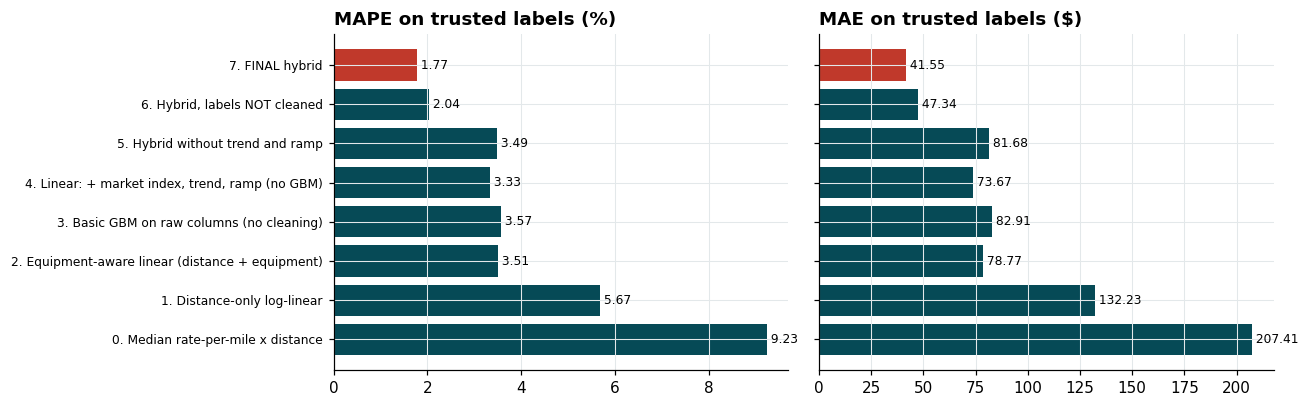

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, col, title in [(axes[0], "MAPE_clean", "MAPE on trusted labels (%)"), (axes[1], "MAE_clean", "MAE on trusted labels ($)")]:
    vals = [summarize(RES[n])[col] for n in ORDER]
    ax.barh(range(len(ORDER)), vals, color=[RED if n.startswith("7") else TEAL for n in ORDER]); ax.set_title(title); ax.invert_yaxis()
    ax.set_yticks(range(len(ORDER)), [n[:52] for n in ORDER], fontsize=8)
    for i, v in enumerate(vals): ax.text(v, i, f" {v:.2f}", va="center", fontsize=8)
fig.tight_layout(); save_fig(fig, P, "model_comparison"); plt.show()

**Interpretation (read the 'trusted labels' columns for model quality, the 'ALL labels' columns for what a scorer including corrupted rows would see).**

* A single dollar-per-mile gives about 9% error; a distance-only log model about 5.7%; adding equipment about 3.5%. Distance and equipment explain most of the price.
* **No single ingredient is enough.** The linear model with market index, trend and ramp but no trees (3.3%), the trees without time terms (3.5%), and the plain GBM on raw columns (3.6%) all plateau around 3.3-3.6%. Only **both together** (linear time/market terms plus trees for weight and geography) reach about 1.8%.
* A basic GBM on raw columns is *not* better than the equipment-aware linear model. A tree model alone cannot extrapolate time effects and is hurt by corrupted labels.
* Cleaning the labels is worth about 0.3 percentage points (2.04% -> 1.77%) on trusted rows.
* Unseen-city rows are only slightly worse (about 1.8% vs 1.75% for seen cities).
* On **all labels** the final model's MAPE is about 4.1% and MAE about $94: that is the realistic expectation for a scorer that includes corrupted validation labels.

**Why the hybrid was selected.** It is the best model on every trusted-label metric, on unseen cities and on all-label metrics; its two parts are individually interpretable; and the part that has to extrapolate (the linear one) is separated from the part that does not (the trees). The benefit over the simple baselines is large (roughly half the error), not marginal.

## 4. How the hybrid works, and is it implemented correctly?

**Question.** What does the linear part learn, what does the tree part add, and does `predict` equal what the maths says?

**Why it matters.** A hybrid is easy to get subtly wrong (for example fitting the trees on the wrong residual).

In [7]:
print(inspect.getsource(FreightRateModel.fit)); print(inspect.getsource(FreightRateModel.predict))

    def fit(self, df: pd.DataFrame, drop_outliers: bool = True):
        df = clean_inputs(df)
        if drop_outliers:
            df = df[flag_label_outliers(df, self.dmi)]
        self.n_train_ = len(df)
        y = np.log(df["posted_rate"].to_numpy())

        L = linear_features(df, self.dmi, **self.opts)
        self.mu_, self.sd_ = L.mean(0), L.std(0) + 1e-9
        self.linear_ = Ridge(alpha=1e-6).fit((L - self.mu_) / self.sd_, y)   # ~ ordinary least squares
        resid = y - self.linear_.predict((L - self.mu_) / self.sd_)

        if self.use_gbm:
            self.gbm_ = HistGradientBoostingRegressor(**self.gbm_params).fit(tree_features(df), resid)
        return self

    def predict(self, df: pd.DataFrame) -> np.ndarray:
        df = clean_inputs(df)
        L = (linear_features(df, self.dmi, **self.opts) - self.mu_) / self.sd_
        log_pred = self.linear_.predict(L)
        if self.use_gbm:
            log_pred = log_pred + self.gbm_.predict(tree_features(df))
      

In [8]:
m = FreightRateModel(dmi).fit(train)
names = ["log_distance", "log_distance^2", "flatbed", "reefer", "daily_market_index", "trend (per 100 days)", "quarter_end_ramp"]
coef = pd.Series(m.linear_.coef_ / m.sd_, index=names)
effect = pd.DataFrame({"coefficient (log-price)": coef, "price effect": np.expm1(coef)})
display(effect.loc[["flatbed", "reefer", "daily_market_index", "trend (per 100 days)", "quarter_end_ramp"]].style.format({"coefficient (log-price)": "{:+.4f}", "price effect": "{:+.2%}"}))
elast = lambda d: coef["log_distance"] + 2 * coef["log_distance^2"] * np.log(d)
display(Markdown("distance elasticity (% price change per 1% distance change): " + ", ".join(f"**{d} mi: {elast(d):.3f}**" for d in (150, 500, 1000, 2000, 3000)) +
                 f";  market index +0.10 -> **{np.expm1(0.1 * coef['daily_market_index']):+.2%}** price"))

# ---- correctness of the hybrid ----
fd = FD[-1]; df = clean_inputs(fd["test"])
manual = np.exp(m.linear_.predict((linear_features(df, dmi) - m.mu_) / m.sd_) + m.gbm_.predict(tree_features(df)))
fitrows = clean_inputs(train); fitrows = fitrows[flag_label_outliers(fitrows, dmi)]
y_fit = np.log(fitrows.posted_rate.to_numpy())
lin_fit = m.linear_.predict((linear_features(fitrows, dmi) - m.mu_) / m.sd_)
gbm_fit = m.gbm_.predict(tree_features(fitrows))
display(Markdown(f"* `predict()` equals exp(linear + trees) computed by hand: **{np.allclose(manual, m.predict(df))}**  \n"
                 f"* all predictions positive and finite: **{bool((m.predict(df) > 0).all() and np.isfinite(m.predict(df)).all())}**  \n"
                 f"* trees were fitted on training leftovers: training log-residual sd **{np.std(y_fit - lin_fit):.4f}** (linear only) -> **{np.std(y_fit - lin_fit - gbm_fit):.4f}** (linear + trees)  \n"
                 f"* rows used for training: **{m.n_train_:,}** of {len(train):,}  \n"
                 f"* trees: **{m.gbm_.n_iter_}** boosting iterations (max {m.gbm_params['max_iter']}); early-stopping setting = **{m.gbm_.early_stopping}** (see section 7c)"))
assert np.allclose(manual, m.predict(df))

,coefficient (log-price),price effect
flatbed,+0.0802,+8.35%
reefer,+0.1215,+12.92%
daily_market_index,+0.1425,+15.31%
trend (per 100 days),+0.0197,+1.99%
quarter_end_ramp,+0.0389,+3.96%


distance elasticity (% price change per 1% distance change): **150 mi: 0.841**, **500 mi: 0.864**, **1000 mi: 0.877**, **2000 mi: 0.891**, **3000 mi: 0.898**;  market index +0.10 -> **+1.44%** price

* `predict()` equals exp(linear + trees) computed by hand: **True**  
* all predictions positive and finite: **True**  
* trees were fitted on training leftovers: training log-residual sd **0.0401** (linear only) -> **0.0183** (linear + trees)  
* rows used for training: **47,323** of 48,000  
* trees: **300** boosting iterations (max 300); early-stopping setting = **auto** (see section 7c)

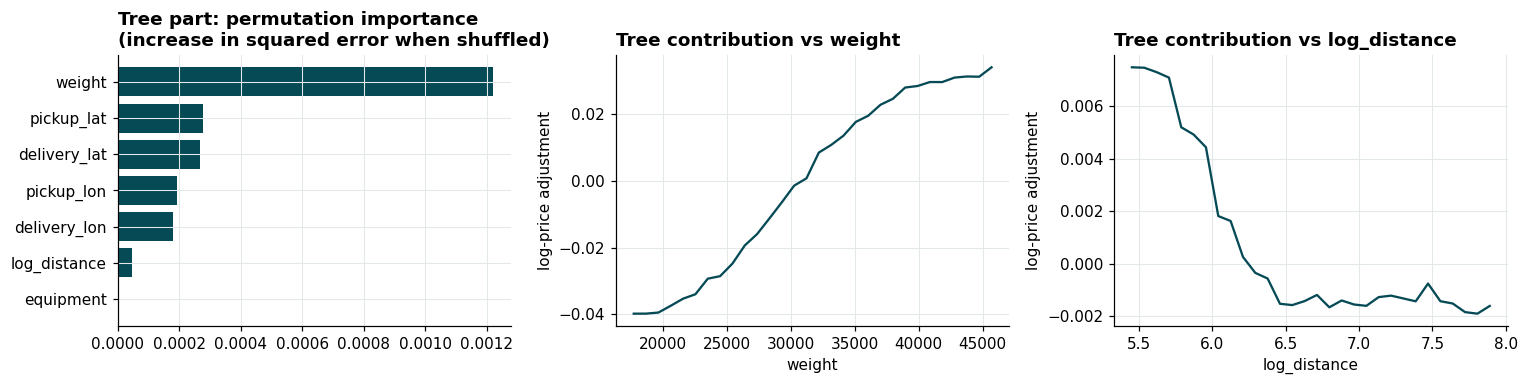

fold-3 trusted rows, R^2 on log price: linear part alone **0.9960**, linear + trees **0.9990**; residual sd (log): **0.0412 -> 0.0203**

In [9]:
# What do the trees add?  Permutation importance on held-out leftovers (fold 3, trusted rows), and partial dependence.
fd = FD[-1]; mf = FreightRateModel(dmi).fit(fd["fit"])
te = clean_inputs(fd["test"])[fd["trusted"]]
resid_target = np.log(te.posted_rate.to_numpy()) - mf.linear_.predict((linear_features(te, dmi) - mf.mu_) / mf.sd_)
Xt = tree_features(te)
pi = permutation_importance(mf.gbm_, Xt, resid_target, n_repeats=5, random_state=0, scoring="neg_mean_squared_error")
imp = pd.Series(pi.importances_mean, index=Xt.columns).sort_values()

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
axes[0].barh(imp.index, imp.values, color=TEAL); axes[0].set_title("Tree part: permutation importance\n(increase in squared error when shuffled)")
for ax, feat in zip(axes[1:], ["weight", "log_distance"]):
    pd_ = partial_dependence(mf.gbm_, Xt.sample(3000, random_state=0), [feat], grid_resolution=30)
    ax.plot(pd_["grid_values"][0], pd_["average"][0], color=TEAL); ax.set_title(f"Tree contribution vs {feat}"); ax.set_xlabel(feat); ax.set_ylabel("log-price adjustment")
fig.tight_layout(); save_fig(fig, P, "tree_component"); plt.show()
r2 = lambda e: 1 - np.var(e) / np.var(np.log(te.posted_rate.to_numpy()))
lin_pred = mf.linear_.predict((linear_features(te, dmi) - mf.mu_) / mf.sd_)
display(Markdown(f"fold-3 trusted rows, R^2 on log price: linear part alone **{r2(np.log(te.posted_rate.to_numpy()) - lin_pred):.4f}**, linear + trees **{r2(resid_target - mf.gbm_.predict(Xt)):.4f}**; "
                 f"residual sd (log): **{np.std(np.log(te.posted_rate.to_numpy()) - lin_pred):.4f} -> {np.std(resid_target - mf.gbm_.predict(Xt)):.4f}**"))

**Interpretation.**
* The linear part reads like a pricing rule: reefer is about 13% and flatbed about 8% above dry van; a 0.10 higher market index adds about 1.4%; price rises with distance with an elasticity of about 0.84-0.90 (so price per mile falls as trips get longer); the drift is about 2% per 100 days; the quarter-end premium reaches about 4%.
* The reconstruction check passes: `predict` is exactly exp(linear + trees), predictions are positive and finite, and the trees do what they are meant to do on the *training leftovers* (log-residual sd roughly 0.040 -> 0.018).
* The trees' contribution is dominated by **geography and weight** (permutation importance chart); the partial-dependence plot for weight is the monotonic, saturating shape found in notebook 2. Held-out R^2 on log price rises from about 0.996 to 0.999 (log-price R^2 is high because price spans orders of magnitude; the residual sd, about 0.041 -> 0.020, is the more informative figure).

Minor note: the trees are fitted to the linear model's *in-sample* residuals. With about 47,000 rows and seven linear parameters, the in-sample residuals are essentially the same as out-of-sample ones, so this is not a practical problem.

## 5. Why a log target?

**Question.** Does predicting log(price) beat predicting dollars, and does the difference matter for the metrics?

**Why it matters.** The target transform changes what the model optimises and where its errors fall.

In [10]:
class RawDollarGBM(NaiveGBM):
    """Same features and settings as NaiveGBM, but fits dollars instead of log-dollars."""
    def fit(self, df, drop_outliers=False):
        from sklearn.ensemble import HistGradientBoostingRegressor
        df = clean_inputs(df); self.m = HistGradientBoostingRegressor(random_state=0).fit(self._x(df), df.posted_rate); return self
    def predict(self, df): return self.m.predict(self._x(clean_inputs(df)))
run("target: log (NaiveGBM)", lambda: NaiveGBM(), False)
run("target: dollars (same GBM)", lambda: RawDollarGBM(), False)
display(comparison(["target: log (NaiveGBM)", "target: dollars (same GBM)"]))

# relative error by price band for both
_, p_log = evaluate(lambda: NaiveGBM(), False, keep_preds=True)
_, p_raw = evaluate(lambda: RawDollarGBM(), False, keep_preds=True)
y_all = np.concatenate([f["test"].posted_rate.to_numpy() for f in FD]); ok_all = np.concatenate([f["trusted"] for f in FD])
band = pd.qcut(y_all[ok_all], 5, labels=["cheapest 20%", "20-40%", "40-60%", "60-80%", "most expensive 20%"])
rel = pd.DataFrame({"log target": np.abs(np.concatenate(p_log)[ok_all] / y_all[ok_all] - 1), "dollar target": np.abs(np.concatenate(p_raw)[ok_all] / y_all[ok_all] - 1)})
display((100 * rel.groupby(band, observed=True).mean()).rename_axis("price band").style.format("{:.2f}").set_caption("mean absolute % error by price band"))

trusted labels               ALL labels              
                                    MAE $ MAPE % RMSE $      MAE $ MAPE % RMSE $
target: log (NaiveGBM)              82.91   3.57 119.35     135.30   5.83 633.65
target: dollars (same GBM)          85.30   3.93 133.18     137.72   6.25 635.53

,log target,dollar target
price band,,
cheapest 20%,3.83,6.09
20-40%,3.86,3.10
40-60%,3.27,3.23
60-80%,3.22,3.32
most expensive 20%,3.65,3.89


**Interpretation.** Holding the model and features fixed, fitting log-dollars gives lower error than fitting dollars (about 3.6% vs 3.9% MAPE, and lower MAE and RMSE as well). The gain is moderate rather than dramatic for a tree model; its main value is for the **linear part**, where multiplicative effects (a 13% reefer premium) become additive and constant. Log fitting also guarantees positive predictions. The cost is that `exp(prediction)` estimates the *median*, not the mean, of a price; with a residual sd of about 0.02 the difference is about 0.02% and is ignored.

## 6. Leakage and legitimacy tests

**Question.** Can any information about test-period labels reach the model? Is the daily market index legitimately usable? Is the label filter fitted without test data?

**Why it matters.** These are the questions a reviewer is most likely to ask. They are answered with experiments, not assertions.

In [11]:
# 6a. Static facts about what the fit() function can see
src = inspect.getsource(FreightRateModel.fit)
display(Markdown("`FreightRateModel.fit` receives only the *training* frame; it calls `flag_label_outliers` on **that frame only** (threshold fitted on training labels) "
                 "and standardises features with the training mean/sd. The test frame is passed only to `predict`, which never reads `posted_rate`."))
te_no_target = FD[-1]["test"].drop(columns="posted_rate")
mm = FreightRateModel(dmi).fit(FD[-1]["fit"])
display(Markdown(f"* predictions identical with and without the target column in the test frame: **{np.array_equal(mm.predict(FD[-1]['test']), mm.predict(te_no_target))}**"))

`FreightRateModel.fit` receives only the *training* frame; it calls `flag_label_outliers` on **that frame only** (threshold fitted on training labels) and standardises features with the training mean/sd. The test frame is passed only to `predict`, which never reads `posted_rate`.

* predictions identical with and without the target column in the test frame: **True**

In [12]:
# 6b. End-to-end leakage experiment with a POSITIVE CONTROL.
# Scramble every label after the cut-off date, rebuild dmi, folds and model from scratch, and compare predictions.
rng = np.random.RandomState(123)
cut = FOLDS[-1][0]                                            # fold 3: train through month 8
def predictions_for(frame):
    d = daily_market_index(frame, valid); folds = make_folds(frame, d); f = folds[-1]
    return FreightRateModel(d).fit(f["fit"]).predict(f["test"])
base = predictions_for(train)

future_scrambled = train.copy()
mask = future_scrambled.date.dt.month > cut
future_scrambled.loc[mask, "posted_rate"] = future_scrambled.loc[mask, "posted_rate"] * rng.lognormal(0, 1.0, mask.sum())
past_scrambled = train.copy()
mask2 = past_scrambled.date.dt.month <= cut
past_scrambled.loc[mask2, "posted_rate"] = past_scrambled.loc[mask2, "posted_rate"] * rng.lognormal(0, 0.3, mask2.sum())

p_future = predictions_for(future_scrambled); p_past = predictions_for(past_scrambled)
display(pd.DataFrame({"max |difference| vs original predictions ($)": [np.abs(p_future - base).max(), np.abs(p_past - base).max()]},
                     index=["test-period labels scrambled (must be 0)", "training-period labels scrambled (must be > 0: positive control)"]))
assert np.array_equal(p_future, base) and np.abs(p_past - base).max() > 1
print("PASS: predictions do not depend on test-period labels, and the experiment is able to detect dependence on training labels.")

,max |difference| vs original predictions ($)
test-period labels scrambled (must be 0),0.00
training-period labels scrambled (must be > 0: positive control),351.81


PASS: predictions do not depend on test-period labels, and the experiment is able to detect dependence on training labels.


In [13]:
# 6c. Is the daily market index usable "at prediction time"?  Compare three ways of supplying it for the test window.
def seasonal_naive(series, last_date):
    """What if the index of a future day is unknown? Use the same weekday of the last fully observed week."""
    alt = series.copy()
    for d in series.index[series.index > last_date]:
        k = int(np.ceil((d - last_date).days / 7)); alt[d] = series[d - pd.Timedelta(days=7 * k)]
    return alt

rows = []
for f in FD:
    y = f["test"].posted_rate.to_numpy(); keep = f["trusted"]
    model = FreightRateModel(dmi).fit(f["fit"])
    alt = seasonal_naive(dmi, f["fit"].date.max())
    variants = {"(a) true daily index from test-day rows (final design)": dmi, "(b) forecast: last week's pattern repeated": alt}
    for name, series in variants.items():
        model.dmi = series; p = model.predict(f["test"]); rows.append(dict(fold=f["fold"], variant=name, **metrics(y[keep], p[keep])))
    none_ = FreightRateModel(dmi, use_market=False).fit(f["fit"]); p = none_.predict(f["test"]); rows.append(dict(fold=f["fold"], variant="(c) no market index at all", **metrics(y[keep], p[keep])))
idx = pd.DataFrame(rows).groupby("variant")[["MAE", "MAPE", "RMSE"]].mean()
display(idx)

,MAE,MAPE,RMSE
variant,,,
(a) true daily index from test-day rows (final design),41.55,1.77,59.90
(b) forecast: last week's pattern repeated,64.25,2.73,89.60
(c) no market index at all,144.64,6.14,184.85


In [14]:
# 6d. Design constants (ramp length, threshold) were chosen while looking at these same folds -> mild optimism.
# Crude check: choose the ramp length on folds 1-2 only, then score it on fold 3.
def mape_for(ramp_days, folds):
    with patched(RAMP_DAYS=ramp_days):
        return evaluate(lambda: FreightRateModel(dmi), True, folds).query("group == 'all rows'").MAPE_clean.to_numpy()
grid = [21, 28, 31, 35, 45]
table = pd.DataFrame({d: mape_for(d, FD) for d in grid}, index=["fold 1", "fold 2", "fold 3"]).T
choice = table.iloc[:, :2].mean(axis=1).idxmin()
display(table.assign(**{"folds 1-2 mean": table.iloc[:, :2].mean(axis=1)}))
display(Markdown(f"ramp length chosen on folds 1-2 only: **{choice} days**; its fold-3 MAPE = **{table.loc[choice, 'fold 3']:.3f}%** vs **{table.loc[31, 'fold 3']:.3f}%** for the shipped 31 days"))

,fold 1,fold 2,fold 3,folds 1-2 mean
21,2.39,1.61,1.68,2.00
28,2.09,1.63,1.65,1.86
31,2.01,1.64,1.65,1.82
35,1.97,1.69,1.67,1.83
45,2.00,1.82,1.74,1.91


ramp length chosen on folds 1-2 only: **31 days**; its fold-3 MAPE = **1.655%** vs **1.655%** for the shipped 31 days

**Interpretation.**
* **Test labels do not influence predictions.** After scrambling every label in the test period and rebuilding the daily index, the folds and the model *from scratch*, the predictions are identical (difference exactly 0). The positive control shows the experiment is capable of detecting dependence: scrambling *training* labels moves predictions by hundreds of dollars. The outlier filter is fitted on the training frame only.
* **The daily market index is the most important legitimacy question.** It uses features of the very rows being predicted (transductive use). For this assessment that is allowed because the file supplies those rows and their index; but a live system would not know a day's index in advance. With a simple forecast (repeat last week's weekly pattern) the error rises from about 1.8% to about 2.7%; with no index at all it is about 6.1%. So the index is **by far the most valuable input**, and the headline accuracy is conditional on having it.
* **Optimism from constants chosen on the same folds.** Choosing the ramp length using only folds 1-2 still selects 31 days and scores identically on fold 3. The tested lengths from 28 to 35 days differ by only about 0.02 percentage points, so this particular choice does not materially inflate the result. Other judgement calls (threshold, features) were also made while looking at all ten months; that residual optimism cannot be measured with this data.

## 7. Hyper-parameter experiments

**Question.** How sensitive are results to the ramp length, the tree settings and the outlier threshold?

**Why it matters.** If results hardly move, further tuning only overfits the folds; if they move a lot, the setting needs justification.

In [15]:
# 7a. Ramp length (from the table above, plus 60 days and 'no ramp')
extra = pd.Series(mape_for(60, FD), index=["fold 1", "fold 2", "fold 3"], name=60)
table2 = pd.concat([table, extra.to_frame().T]).sort_index()
none_ramp = evaluate(lambda: FreightRateModel(dmi, use_ramp=False), True).query("group == 'all rows'").MAPE_clean.to_numpy()
table2.loc["no ramp"] = none_ramp
table2["mean"] = table2.mean(axis=1); display(table2.round(3))

,fold 1,fold 2,fold 3,mean
21,2.39,1.61,1.68,1.90
28,2.09,1.63,1.65,1.79
31,2.00,1.64,1.66,1.77
35,1.97,1.69,1.67,1.78
45,2.00,1.82,1.74,1.85
60,2.29,2.07,1.86,2.07
no ramp,4.72,1.94,2.02,2.89


In [16]:
# 7b. Tree settings (everything else fixed)
settings = {
    "shipped: 300 it, lr 0.05, 15 leaves, min leaf 60": {},
    "7 leaves": dict(max_leaf_nodes=7), "31 leaves": dict(max_leaf_nodes=31),
    "min leaf 20": dict(min_samples_leaf=20), "min leaf 150": dict(min_samples_leaf=150),
    "100 it": dict(max_iter=100), "600 it, lr 0.025": dict(max_iter=600, learning_rate=0.025),
}
rows = []
for name, params in settings.items():
    s = summarize(evaluate(lambda: FreightRateModel(dmi, gbm_params=params), True)); rows.append({"setting": name, "MAPE % (trusted)": s.MAPE_clean, "MAE $": s.MAE_clean})
display(pd.DataFrame(rows).set_index("setting"))

,MAPE % (trusted),MAE $
setting,,
"shipped: 300 it, lr 0.05, 15 leaves, min leaf 60",1.77,41.55
7 leaves,1.78,41.87
31 leaves,1.76,41.44
min leaf 20,1.77,41.59
min leaf 150,1.77,41.60
100 it,1.80,42.26
"600 it, lr 0.025",1.77,41.65


In [17]:
# 7c. A DISCOVERED DETAIL: HistGradientBoostingRegressor defaults to early_stopping='auto',
#     which is ON for more than 10,000 rows and silently holds out a random 10% of the training rows.
default_model = FreightRateModel(dmi).fit(FD[-1]["fit"])
display(Markdown(f"default early_stopping setting on this data: **{default_model.gbm_.early_stopping}**, "
                 f"`do_early_stopping_` = **{default_model.gbm_.do_early_stopping_}**, iterations run = **{default_model.gbm_.n_iter_}** of {default_model.gbm_params['max_iter']}, "
                 f"internal validation scores recorded = **{len(default_model.gbm_.validation_score_)}**"))
rows = []
for name, params in {"early_stopping='auto' (shipped default: 10% of rows held out inside the GBM)": {}, "early_stopping=False (all rows train the trees)": dict(early_stopping=False)}.items():
    s = summarize(evaluate(lambda: FreightRateModel(dmi, gbm_params=params), True)); su = summarize(evaluate(lambda: FreightRateModel(dmi, gbm_params=params), True), "unseen cities")
    rows.append({"setting": name, "MAPE % (trusted)": s.MAPE_clean, "MAE $": s.MAE_clean, "MAPE % (unseen cities)": su.MAPE_clean})
display(pd.DataFrame(rows).set_index("setting"))

default early_stopping setting on this data: **auto**, `do_early_stopping_` = **True**, iterations run = **300** of 300, internal validation scores recorded = **301**

,MAPE % (trusted),MAE $,MAPE % (unseen cities)
setting,,,
early_stopping='auto' (shipped default: 10% of rows held out inside the GBM),1.77,41.55,1.81
early_stopping=False (all rows train the trees),1.77,41.60,1.83


In [18]:
# 7d. Outlier threshold used for training-time label filtering (test rows judged with the same fixed 'trusted' mask)
rows = []
for thr in (0.25, 0.4, 0.6, 0.8):
    with patched(OUTLIER_LOG_THRESHOLD=thr):
        s = summarize(evaluate(lambda: FreightRateModel(dmi), True)); n_drop = int((~flag_label_outliers(clean_inputs(FD[-1]["fit"]), dmi)).sum())
    rows.append({"threshold": thr, "rows dropped (fold 3 train)": n_drop, "MAPE % (trusted)": s.MAPE_clean, "MAE $": s.MAE_clean})
s = summarize(RES["6. Hybrid, labels NOT cleaned"]); rows.append({"threshold": "no cleaning", "rows dropped (fold 3 train)": 0, "MAPE % (trusted)": s.MAPE_clean, "MAE $": s.MAE_clean})
display(pd.DataFrame(rows).set_index("threshold"))

,rows dropped (fold 3 train),MAPE % (trusted),MAE $
threshold,,,
0.25,390,1.77,41.55
0.40,390,1.77,41.55
0.60,390,1.77,41.55
0.80,389,1.76,41.44
no cleaning,0,2.04,47.34


**Interpretation.**
* **Ramp length** matters little between 28 and 35 days; very long ramps (60 days) and no ramp at all are clearly worse.
* **Tree settings** hardly matter (all variants within about 0.03 percentage points): further tuning would only fit the folds.
* **A discovered implementation detail.** `HistGradientBoostingRegressor` silently turns on early stopping for more than 10,000 rows, which holds out a random 10% of the training rows *inside* the GBM. The stopping rule never triggered (all 300 iterations ran), so those 10% of rows were simply not used by the trees, and the random split can differ between library versions (we measured differences of about 0.1% on average between two environments). Switching it off gives the same accuracy (1.77% vs 1.77% trusted), so this affects **reproducibility, not accuracy**. Recommended fix: set `early_stopping=False` explicitly in `common.py`; it has **not** been applied, so the submitted numbers still come from the original code.
* **Outlier threshold**: anywhere from 0.25 to 0.8 drops essentially the same rows and gives the same error; not cleaning at all is clearly worse. The conclusion does not depend on the threshold.

## 8. Ablations and placebo tests

**Question.** Remove or add one ingredient at a time. Is the quarter-end ramp really quarter-specific? What does excluding `quote_signal` and the row-level index cost?

**Why it matters.** Ablations show which parts of the model carry the performance; placebo tests show whether a discovered pattern could be an artefact.

In [19]:
orig_lin, orig_tree = common.linear_features, common.tree_features
def lin_plus(extra_fn):
    return lambda df, dmi_, **kw: np.column_stack([orig_lin(df, dmi_, **kw), extra_fn(df)])
row_dev_mi = lambda df: (df.market_index - df.date.map(dmi)).fillna(0).to_numpy()
row_dev_qs = lambda df: (df.quote_signal - df.date.map(dqs)).to_numpy()
daily_qs   = lambda df: df.date.map(dqs).to_numpy()
def tree_drop(cols): return lambda df: orig_tree(df).drop(columns=cols)
def tree_add_qs(df): return orig_tree(df).assign(row_qs=df.quote_signal.to_numpy())

ABL = {
    "FINAL (reference)": ({}, dict()),
    "- trend": ({}, dict(use_trend=False)), "- quarter-end ramp": ({}, dict(use_ramp=False)),
    "- market index": ({}, dict(use_market=False)), "- trees (linear only)": ({}, dict(use_gbm=False)),
    "- coordinates in trees": (dict(tree_features=tree_drop(COORD_COLS)), dict()),
    "- weight in trees": (dict(tree_features=tree_drop(["weight"])), dict()),
    "+ row-level market-index deviation": (dict(linear_features=lin_plus(row_dev_mi)), dict()),
    "+ row-level quote_signal deviation (linear)": (dict(linear_features=lin_plus(row_dev_qs)), dict()),
    "+ both row-level deviations": (dict(linear_features=lin_plus(lambda d: np.column_stack([row_dev_mi(d), row_dev_qs(d)]))), dict()),
    "+ daily quote_signal (linear)": (dict(linear_features=lin_plus(daily_qs)), dict()),
    "+ row quote_signal in trees": (dict(tree_features=tree_add_qs), dict()),
}
abl_rows = {}
for name, (patch, kw) in ABL.items():
    with patched(**patch):
        df_ = evaluate(lambda: FreightRateModel(dmi, **kw), True)
    abl_rows[name] = {"MAPE % (trusted)": summarize(df_).MAPE_clean, "MAE $": summarize(df_).MAE_clean, "MAPE % unseen cities": summarize(df_, "unseen cities").MAPE_clean,
                      **{f"fold {r.fold}": r.MAPE_clean for r in df_[df_.group == "all rows"].itertuples()}}
abl = pd.DataFrame(abl_rows).T
abl["change vs final (pp)"] = abl["MAPE % (trusted)"] - abl.loc["FINAL (reference)", "MAPE % (trusted)"]
display(abl.round(3))

,MAPE % (trusted),MAE $,MAPE % unseen cities,fold 1,fold 2,fold 3,change vs final (pp)
FINAL (reference),1.77,41.55,1.81,2.00,1.64,1.66,0.00
- trend,3.21,74.83,3.25,2.58,3.29,3.75,1.44
- quarter-end ramp,2.89,67.66,2.92,4.72,1.94,2.02,1.12
- market index,6.14,144.64,6.12,6.60,7.32,4.51,4.38
- trees (linear only),3.33,73.67,3.19,3.37,3.27,3.35,1.56
- coordinates in trees,2.60,55.58,2.42,2.70,2.53,2.56,0.83
- weight in trees,2.72,63.54,2.76,2.84,2.64,2.69,0.96
+ row-level market-index deviation,1.75,41.17,1.81,2.00,1.63,1.64,-0.01
+ row-level quote_signal deviation (linear),1.78,42.08,1.82,2.08,1.61,1.64,0.01
+ both row-level deviations,1.76,41.63,1.82,2.08,1.59,1.62,-0.00


In [20]:
# Placebo tests for the quarter-end ramp: swap the calendar mapping for plausible-but-wrong ones.
def dtm_month_end(dates): return ((dates.dt.to_period("M").dt.end_time.dt.normalize() - dates).dt.days).to_numpy()
def dtq_shifted(dates):   return (days_to_quarter_end(dates) + 45) % 91          # same shape, wrong place in the quarter
PL = {"true quarter-end ramp (final)": common.days_to_quarter_end, "placebo A: ramp before EVERY month-end": dtm_month_end,
      "placebo B: ramp misplaced by 45 days": dtq_shifted}
rows = {}
for name, fn in PL.items():
    with patched(days_to_quarter_end=fn):
        d_ = evaluate(lambda: FreightRateModel(dmi), True)
    rows[name] = {"MAPE % (trusted)": summarize(d_).MAPE_clean, **{f"fold {r.fold}": r.MAPE_clean for r in d_[d_.group == "all rows"].itertuples()}}
rows["no ramp at all"] = {"MAPE % (trusted)": abl.loc["- quarter-end ramp", "MAPE % (trusted)"], **{f"fold {k}": abl.loc["- quarter-end ramp", f"fold {k}"] for k in (1, 2, 3)}}
display(pd.DataFrame(rows).T.round(3))

# Genuine out-of-sample test of the ramp: train through August (two quarter-ends seen: March, June), test September alone.
fit_ = train[train.date.dt.month <= 8]; sep = clean_inputs(train[train.date.dt.month == 9]); okS = flag_label_outliers(sep, dmi); yS = sep.posted_rate.to_numpy()
late = (sep.date.dt.day >= 16).to_numpy()
rows = []
for name, kw in {"with ramp": {}, "without ramp": dict(use_ramp=False), "without ramp and trend": dict(use_ramp=False, use_trend=False)}.items():
    p = FreightRateModel(dmi, **kw).fit(fit_).predict(sep)
    rows.append({"model (trained Jan-Aug)": name, "September MAPE %": 100 * np.mean(np.abs(p / yS - 1)[okS]), "Sep 16-30 MAPE %": 100 * np.mean(np.abs(p / yS - 1)[okS & late]), "Sep 16-30 mean bias %": 100 * np.mean((p / yS - 1)[okS & late])})
display(pd.DataFrame(rows).set_index("model (trained Jan-Aug)").round(2))

,MAPE % (trusted),fold 1,fold 2,fold 3
true quarter-end ramp (final),1.77,2.00,1.64,1.66
placebo A: ramp before EVERY month-end,2.82,4.58,1.86,2.03
placebo B: ramp misplaced by 45 days,2.69,4.34,1.84,1.90
no ramp at all,2.89,4.72,1.94,2.02


,September MAPE %,Sep 16-30 MAPE %,Sep 16-30 mean bias %
model (trained Jan-Aug),,,
with ramp,1.63,1.84,-0.07
without ramp,2.43,3.23,-3.04
without ramp and trend,4.83,6.03,-6.03


**Interpretation.**
* **What carries the performance** (change in MAPE when removed): market index +4.4 points, trees +1.6, trend +1.4, ramp +1.1, weight +1.0, coordinates +0.8. Every component earns its place.
* **The ramp and the trend interact.** Removing the ramp hurts most in fold 1 (about 4.7% vs 2.0%) even though that test window (Jul-Aug) contains no quarter-end: without a ramp, the trend is estimated from data containing the end-of-June spike and then over-predicts July-August. So the quarter-end term is partly a protection for the trend estimate. This is a further sign that the trend and calendar terms are **entangled**; their sum is better supported than each separately.
* **The ramp is not an artefact of any calendar.** Placing a similar ramp before every month-end, or misplacing it by 45 days, gives no improvement over having *no* ramp (about 2.7-2.8% vs 2.9%), while the true quarter-end placement gives 1.77%. In the genuine out-of-sample test (train Jan-Aug, test September) the ramp removes a systematic -3% bias in the last two weeks of September. That is support for Q1-Q3; it is still **three observations of a pattern**, and Q4 has not been observed.
* **What excluding `quote_signal` and the row-level deviations costs.** Adding the row-level `market_index` deviation, the row-level `quote_signal` deviation, or the daily `quote_signal` to the linear part changes MAPE by 0.01 points or less. The only visible gain is the row-level `quote_signal` in the trees: about 0.04 points (1.77% to 1.73%), consistent in two folds and neutral in one. That is small and within the noise of three folds; excluding it is a defensible, low-risk simplification, **but it is a measured cost, not zero**.

## 9. Residual analysis

**Question.** Where does the final model make errors, and is any structure left?

**Why it matters.** Structure in residuals means the model is missing something; it also shows where the quoted average hides weaknesses.

out-of-fold rows: **28,623** (trusted **28,214**);  log-residual mean **-0.0057**, sd **0.0212**;  share of trusted rows within 2% / 5% / 10%: **63.1% / 97.6% / 100.0%**

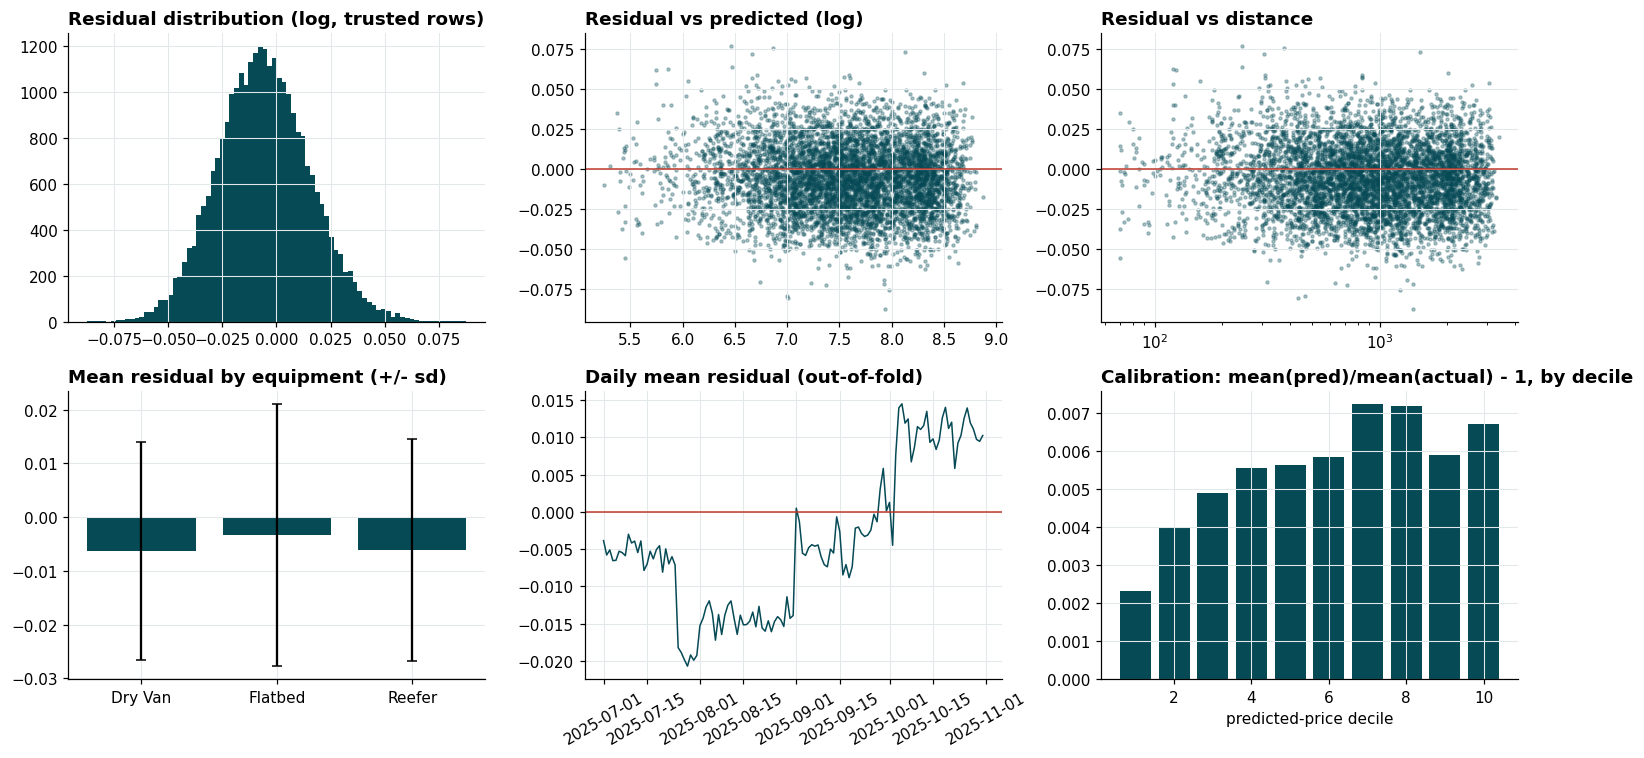

,seen cities,unseen cities
log-residual sd,0.02,0.02
MAPE %,1.75,1.82


,mean log residual,sd
fold,,
1,-0.01,0.02
2,-0.01,0.02
3,0.01,0.02


daily mean residual: sd **0.0099**, lag-1 autocorrelation **0.95**, lag-7 **0.84**

In [21]:
df_, preds = evaluate(lambda: FreightRateModel(dmi), True, keep_preds=True)
oof = pd.concat([f["test"].assign(pred=p, trusted=f["trusted"], unseen=f["unseen"], fold=f["fold"]) for f, p in zip(FD, preds)])
oof["log_res"] = np.log(oof.posted_rate) - np.log(oof.pred); oof["rel_err"] = oof.pred / oof.posted_rate - 1
t = oof[oof.trusted]
display(Markdown(f"out-of-fold rows: **{len(oof):,}** (trusted **{len(t):,}**);  log-residual mean **{t.log_res.mean():+.4f}**, sd **{t.log_res.std():.4f}**;  "
                 f"share of trusted rows within 2% / 5% / 10%: **{(t.rel_err.abs() < .02).mean():.1%} / {(t.rel_err.abs() < .05).mean():.1%} / {(t.rel_err.abs() < .10).mean():.1%}**"))

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
axes[0, 0].hist(t.log_res, bins=80, color=TEAL); axes[0, 0].set_title("Residual distribution (log, trusted rows)")
s = t.sample(6000, random_state=0); axes[0, 1].scatter(np.log(s.pred), s.log_res, s=4, alpha=0.3, color=TEAL); axes[0, 1].axhline(0, color=RED, lw=1); axes[0, 1].set_title("Residual vs predicted (log)")
axes[0, 2].scatter(s.distance, s.log_res, s=4, alpha=0.3, color=TEAL); axes[0, 2].axhline(0, color=RED, lw=1); axes[0, 2].set_xscale("log"); axes[0, 2].set_title("Residual vs distance")
g = t.groupby("equipment").log_res.agg(["mean", "std"]); axes[1, 0].bar(g.index, g["mean"], yerr=g["std"], color=TEAL, capsize=3); axes[1, 0].set_title("Mean residual by equipment (+/- sd)")
dm = t.groupby("date").log_res.mean(); axes[1, 1].plot(dm.index, dm.values, color=TEAL, lw=1); axes[1, 1].axhline(0, color=RED, lw=1); axes[1, 1].set_title("Daily mean residual (out-of-fold)"); axes[1, 1].tick_params(axis="x", rotation=30)
calib = t.groupby(pd.qcut(t.pred, 10, labels=False)).apply(lambda d: d.pred.mean() / d.posted_rate.mean(), include_groups=False)
axes[1, 2].bar(calib.index + 1, calib.values - 1, color=TEAL); axes[1, 2].set_title("Calibration: mean(pred)/mean(actual) - 1, by decile"); axes[1, 2].set_xlabel("predicted-price decile")
fig.tight_layout(); save_fig(fig, P, "residuals"); plt.show()

display(pd.DataFrame({"seen cities": [t[~t.unseen].log_res.std(), t[~t.unseen].rel_err.abs().mean() * 100],
                      "unseen cities": [t[t.unseen].log_res.std(), t[t.unseen].rel_err.abs().mean() * 100]}, index=["log-residual sd", "MAPE %"]))
display(t.groupby("fold").log_res.agg(["mean", "std"]).rename(columns={"mean": "mean log residual", "std": "sd"}))
display(Markdown(f"daily mean residual: sd **{dm.std():.4f}**, lag-1 autocorrelation **{dm.autocorr(1):.2f}**, lag-7 **{dm.autocorr(7):.2f}**"))

**Interpretation.**
* **Typical accuracy on trusted rows:** about 63% of predictions are within 2% of the true price, about 98% within 5% and essentially all within 10%. Residuals look symmetric; patterns against predicted price, distance and equipment are weak (correlation of the residual with log distance about -0.06). Calibration by predicted-price decile is within about +0.2% to +0.7%, i.e. a **consistent small over-prediction of roughly 0.6%**, which is small but systematic.
* **Unseen cities** are slightly worse than seen cities, as expected.
* **What is left: a persistent daily error.** The daily mean residual has sd about 0.01 (1%) with lag-1 autocorrelation about 0.95 and lag-7 about 0.84. Averaging about 150 independent rows per day would leave only about 0.2% of noise, so this is *systematic*: on some stretches of days the model is consistently about 1% off. That is a smooth, unmodelled time factor, and it is the main reason the model is above the noise floor. It is also the main **risk for November-December**, where an unmodelled time factor could be larger (no labels exist to check). It was visible in-sample (notebook 1) and the model captures most but not all of it.

## 10. Are the metrics computed correctly, and what do 'trusted' and 'all' mean?

**Question.** Do the project's metric functions agree with an independent implementation, and how much do the corrupted labels distort each metric?

**Why it matters.** A metric bug would invalidate every comparison above; and Spotter's number will almost certainly be an 'all labels' number.

In [22]:
y_all = oof.posted_rate.to_numpy(); p_all = oof.pred.to_numpy(); tr_mask = oof.trusted.to_numpy()
ours = metrics(y_all[tr_mask], p_all[tr_mask])
sk = {"MAE": mean_absolute_error(y_all[tr_mask], p_all[tr_mask]), "MAPE": 100 * mean_absolute_percentage_error(y_all[tr_mask], p_all[tr_mask]),
      "RMSE": float(np.sqrt(mean_squared_error(y_all[tr_mask], p_all[tr_mask])))}
display(pd.DataFrame({"project metrics()": ours, "scikit-learn": sk}))
assert all(np.isclose(ours[k], sk[k]) for k in ours); print("PASS: project metrics agree with scikit-learn.")

allm = metrics(y_all, p_all); sq = (p_all - y_all) ** 2
display(pd.DataFrame({"trusted labels only": ours, "ALL labels (incl. corrupted)": allm}).T)
abs_err = np.abs(p_all - y_all)
display(Markdown(f"* corrupted rows are **{(~tr_mask).mean():.2%}** of out-of-fold rows but contribute **{sq[~tr_mask].sum() / sq.sum():.1%} of the total squared error** (what RMSE sees) "
                 f"and **{abs_err[~tr_mask].sum() / abs_err.sum():.1%} of the total absolute error** (what MAE sees)"))

,project metrics(),scikit-learn
MAE,41.59,41.59
MAPE,1.77,1.77
RMSE,60.21,60.21


PASS: project metrics agree with scikit-learn.


,MAE,MAPE,RMSE
trusted labels only,41.59,1.77,60.21
ALL labels (incl. corrupted),94.52,4.14,620.21


* corrupted rows are **1.43%** of out-of-fold rows but contribute **99.1% of the total squared error** (what RMSE sees) and **56.6% of the total absolute error** (what MAE sees)

**Interpretation.**
* The project's `metrics()` agree with scikit-learn exactly, so the numbers are computed correctly. (Pooled out-of-fold MAE here, $41.59, differs from the fold-average $41.55 only because folds have slightly different sizes.)
* **Corrupted labels are 1.4% of rows but about 99% of the total squared error and about 57% of the total absolute error.** So the choice of metric by the scorer determines how bad the final number looks: RMSE will be dominated by corrupted validation labels (if any exist there); MAE is half affected; MAPE is affected too. On all labels the final model gives MAE about $94, MAPE about 4.1% and RMSE about $620.
* Therefore: *do not compare Spotter's number with the 1.77% figure.* The 1.77% is a clean-label, forward-in-time estimate for rows with credible labels; the realistic all-label figures are in the table above.

## 11. Model selection, limits and verified claims

**Question.** Which model should be submitted, and what exactly do the validation numbers support?

**Why it matters.** The decision must follow from the evidence above, with its limits stated.

In [23]:
final_s, unseen_s = summarize(RES["7. FINAL hybrid"]), summarize(RES["7. FINAL hybrid"], "unseen cities")
claims = pd.DataFrame([
    ("Hybrid linear + gradient-boosting model is what is implemented", "VERIFIED", "FreightRateModel.fit/predict; manual reconstruction matches (section 4)"),
    ("Forward-in-time validation is used", "VERIFIED", "3 expanding-window folds, test always after train (section 1)"),
    ("Clean-label MAPE about 1.77%", "VERIFIED (as defined)", f"reproduced: {final_s.MAPE_clean:.2f}% on trusted rows; on ALL labels: {final_s.MAPE_all:.2f}%"),
    ("Unseen cities handled", "VERIFIED in simulation", f"unseen-city rows: {unseen_s.MAPE_clean:.2f}% MAPE (trusted labels)"),
    ("Outlier threshold fitted on training data only", "VERIFIED", "fit() filters its own frame; scramble test with positive control (section 6b)"),
    ("Test labels never influence fitting", "VERIFIED", "section 6b: identical predictions when test-period labels are scrambled"),
    ("~1.4% of labels corrupted", "VERIFIED in training data", "677 of 48,000 flagged; cannot be checked in validation (no labels)"),
    ("Quarter-end ramp is real", "SUPPORTED for Q1-Q3; UNVERIFIED for Q4", "beats placebos and works out-of-sample for September (section 8); December is extrapolation"),
    ("Temporal drift is not seasonality", "NOT VERIFIABLE", "10 months of one year cannot separate them"),
    ("Daily market index available at prediction time", "VERIFIED for this task; NOT in live forecasting", "section 6c quantifies the cost of not having it"),
    ("quote_signal is an unstable proxy", "PLAUSIBLE, not proven", "sign flips and co-movement with the ramp; ablation shows its small effect (section 8)"),
], columns=["claim", "status", "evidence"])
display(claims.set_index("claim"))

,status,evidence
claim,,
Hybrid linear + gradient-boosting model is what is implemented,VERIFIED,FreightRateModel.fit/predict; manual reconstru...
Forward-in-time validation is used,VERIFIED,"3 expanding-window folds, test always after tr..."
Clean-label MAPE about 1.77%,VERIFIED (as defined),reproduced: 1.77% on trusted rows; on ALL labe...
Unseen cities handled,VERIFIED in simulation,unseen-city rows: 1.81% MAPE (trusted labels)
Outlier threshold fitted on training data only,VERIFIED,fit() filters its own frame; scramble test wit...
Test labels never influence fitting,VERIFIED,section 6b: identical predictions when test-pe...
~1.4% of labels corrupted,VERIFIED in training data,"677 of 48,000 flagged; cannot be checked in va..."
Quarter-end ramp is real,SUPPORTED for Q1-Q3; UNVERIFIED for Q4,beats placebos and works out-of-sample for Sep...
Temporal drift is not seasonality,NOT VERIFIABLE,10 months of one year cannot separate them


**Selection.** Submited the final hybrid. It is the best-performing model by a wide margin on every comparison, is interpretable, and its failure modes are known and isolated: the three time-related terms (market index, trend, ramp) are explicit and can be inspected or removed.

**What this validation does and does not support.**
* Supported: forward-in-time accuracy of about 1.8% (trusted labels) / 4.1% (all labels) for loads with an available daily market index, including loads in cities never seen in training.
* Supported with caveats: the quarter-end ramp (three of three quarters, beats placebos, works for September out-of-sample).
* **Not supported / not testable here:** (1) that the ramp occurs at the end of Q4; (2) that the drift is not part of an annual seasonal cycle; (3) accuracy when the daily index must be forecast (about 2.7% in a crude test); (4) the effect of December holidays; (5) a persistent ~1% daily error remains unexplained.
* **Selection bias:** design constants were chosen on the same ten months; the true out-of-sample error is probably somewhat higher than the cross-validated figure.

**Recommended follow-ups (none applied, to keep the submission reproducible from the original code):** set `early_stopping=False`; report both clean and all-label metrics (as done); consider the row-level `quote_signal` in the trees only if you are comfortable with its regime risk (a measured 0.04-point gain).

**Next:** `04_final_predictions_and_submission.ipynb` reproduces the submission.